# Colab runner — RoBERTa LOBO sweep

Dartmouth JupyterHub had no GPU, so this runs the GPU work on a Colab **T4**.

**Runtime → Change runtime type → T4 GPU** before you start.

### The one thing that matters here
Free Colab disconnects (~90 min idle, ~4 h max) and wipes the local disk. So results are
written to **Google Drive**, not to the project folder. Every fold that finishes is saved
permanently; re-running a cell after a disconnect skips the folds already done.

Run the stages in order. If you get disconnected, reconnect and re-run from **Stage 4** —
it picks up where it stopped.

## Stage 0 — confirm you actually have a GPU

In [1]:
!nvidia-smi
import torch
print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > T4 GPU"
print("device:", torch.cuda.get_device_name(0))

Fri Oct 23 19:42:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Stage 1 — mount Drive and choose where results live

Everything written under `WCB_RESULTS_DIR` survives a disconnect.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, pathlib
DRIVE_ROOT = '/content/drive/MyDrive/cs72_final_project'
os.environ['WCB_RESULTS_DIR'] = f'{DRIVE_ROOT}/results'
os.environ['WCB_FIGURES_DIR'] = f'{DRIVE_ROOT}/figures'
for p in (os.environ['WCB_RESULTS_DIR'], os.environ['WCB_FIGURES_DIR']):
    pathlib.Path(p).mkdir(parents=True, exist_ok=True)
print('results ->', os.environ['WCB_RESULTS_DIR'])

Mounted at /content/drive
results -> /content/drive/MyDrive/cs72_final_project/results


## Stage 2 — get the code onto Colab

**Pick ONE.** Option A is better if you have a GitHub repo (and you want one anyway for a
final project). Option B needs no setup: zip the project on your Mac, drop the zip in the
Drive folder above.

In [3]:
# ---- Option A: clone from GitHub -------------------------------------------------
# !git clone https://github.com/<you>/<repo>.git /content/final_project

# ---- Option B: unzip an archive you put in Drive ----------------------------------
# On your Mac, from the parent of final_project/:
#   zip -r final_project.zip final_project -x '*/.venv/*' '*/__pycache__/*' '*/.git/*'
# then upload final_project.zip into the Drive folder from Stage 1.
!rm -rf /content/final_project
!unzip -q {DRIVE_ROOT}/final_project.zip -d /content/
import os; os.chdir('/content/final_project')
!ls

'CS 72 Project Proposal.pdf'   pyproject.toml	  results
 figures		       README.md	  scripts
 notebooks		       requirements.txt   src


## Stage 3 — install dependencies

**Do not install torch.** Colab's build is matched to its CUDA driver; replacing it
breaks GPU support. `--no-deps` on the project install stops pip from re-resolving
(and downgrading) what Colab already ships.

In [4]:
!pip install -q datasets transformers nltk
!pip install -q -e . --no-deps
import nltk; nltk.download('punkt_tab', quiet=True)

import sys, os, pathlib
# pip's editable install writes a .pth file, but site-packages paths are only read at
# interpreter startup -- so this already-running kernel cannot see the new package.
# Adding src/ to sys.path makes it importable without restarting (which would drop the
# Drive mount and the env vars from Stage 1).
root = next((p for p in ('/content/final_project', '/content/final_project/final_project')
             if pathlib.Path(p, 'src', 'wcb', 'config.py').exists()), None)
assert root, "couldn't find src/wcb - check Stage 2 actually unzipped"
os.chdir(root)
if f'{root}/src' not in sys.path:
    sys.path.insert(0, f'{root}/src')

from wcb import config as C
print('project :', root)
print('banks   :', len(C.BANKS))
print('results :', C.RESULTS_DIR)
assert str(C.RESULTS_DIR).startswith('/content/drive'), 'results are NOT on Drive - re-run Stage 1'
print('\nOK - carry on to Stage 4')

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for wcb-transfer (pyproject.toml) ... done
project : /content/final_project
banks   : 25
results : /content/drive/MyDrive/cs72_final_project/results

OK - carry on to Stage 4


In [ ]:
import sys, os, pathlib

# Locate the extracted project, then make it importable in THIS kernel.
# pip's editable install registered a .pth file, but site-packages paths are only
# read at interpreter startup, so a running kernel can't see it without a restart.
root = next((p for p in ('/content/final_project', '/content/final_project/final_project')
              if pathlib.Path(p, 'src', 'wcb', 'config.py').exists()), None)
assert root, "couldn't find src/wcb - check Stage 2 actually unzipped"

os.chdir(root)
if f'{root}/src' not in sys.path:
    sys.path.insert(0, f'{root}/src')

from wcb import config as C
print('project  :', root)
print('banks    :', len(C.BANKS))
print('results  :', C.RESULTS_DIR)
assert str(C.RESULTS_DIR).startswith('/content/drive'), 'results are NOT on Drive - re-run Stage 1'
print('\nOK - Drive is wired up, carry on to Stage 4')

project  : /content/final_project
banks    : 25
results  : /content/drive/MyDrive/cs72_final_project/results

OK - Drive is wired up, carry on to Stage 4


## Stage 4 — time one fold

Do this before committing hours. It prints how many folds fit in a session.

Expect roughly **4–10 min/fold** on a T4. Sentences average 34 tokens and the collator
pads per batch rather than to 128, so this usually lands at the fast end.

In [ ]:
import os
from google.colab import userdata
os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
print('HF token loaded:', bool(os.environ.get('HF_TOKEN')))

HF token loaded: True


In [ ]:
!python scripts/run_roberta.py --condition lobo --banks ecb --time-only

device: cuda
no selected_hparams.json found -- falling back to config defaults

=== seed 5768 ===
dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)

-- lobo_ecb  train=16752  val=3593  held_out=ecb
Loading weights: 100% 197/197 [00:00<00:00, 5458.23it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized

## Stage 5 — pick hyperparameters once

Four runs over the WCB paper's grid, selected on the pooled validation split and then
frozen for all 25 folds. Skip this and the defaults (lr 1e-5, batch 32) are used.

In [ ]:
!python scripts/run_roberta.py --hparam-search

device: cuda
dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)
grid: batch_size=32 lr=1e-05
Loading weights: 100% 197/197 [00:00<00:00, 4959.47it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
    epoch 1/4  loss=0.946

## Stage 6 — the sweep, staged so a disconnect still leaves a result

Run these **in order**. Each is independently resumable; the ordering means that even if
you lose the session partway you have something coherent to write up.

| cell | folds | time | what you have afterwards |
|---|---|---|---|
| 6a | 2 | ~10 min | ceiling + size control for all 25 banks |
| 6b | 5 | ~25 min | a complete story for the 5 focus banks |
| 6c | 20 | ~2–3 h | the full 25-bank sweep |

In [ ]:
# 6a - pooled + size control (also saves the checkpoint the demo and Czech check need)
!python scripts/run_roberta.py --condition pooled size_control

device: cuda
using frozen hyperparameters from selected_hparams.json: {'batch_size': 32, 'learning_rate': 1e-05}

=== seed 5768 ===
dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)

-- pooled  train=17468  val=3749  held_out=None
Loading weights: 100% 197/197 [00:00<00:00, 5317.31it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	th

In [ ]:
 # === RESUME after a disconnect ===
import os, sys, pathlib

# 1. GPU first - a reconnect can land you on a CPU runtime
import torch
assert torch.cuda.is_available(), "No GPU. Runtime > Change runtime type > T4 GPU, then re-run"
print('GPU:', torch.cuda.get_device_name(0))

# 2. Re-mount Drive and point results back at it
from google.colab import drive
drive.mount('/content/drive')
DRIVE_ROOT = '/content/drive/MyDrive/cs72_final_project'
os.environ['WCB_RESULTS_DIR'] = f'{DRIVE_ROOT}/results'
os.environ['WCB_FIGURES_DIR'] = f'{DRIVE_ROOT}/figures'

# 3. /content was wiped - re-extract the code
!rm -rf /content/final_project
!unzip -q {DRIVE_ROOT}/final_project.zip -d /content/

# 4. Reinstall deps (also wiped). Still no torch - Colab's is already correct.
!pip install -q datasets transformers nltk
!pip install -q -e /content/final_project --no-deps
import nltk; nltk.download('punkt_tab', quiet=True)

root = '/content/final_project'
os.chdir(root)
if f'{root}/src' not in sys.path:
    sys.path.insert(0, f'{root}/src')

from wcb import config as C
print('results dir:', C.RESULTS_DIR)
assert str(C.RESULTS_DIR).startswith('/content/drive'), 'Drive not wired up'

GPU: Tesla T4
Mounted at /content/drive
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for wcb-transfer (pyproject.toml) ... done
results dir: /content/drive/MyDrive/cs72_final_project/results


In [ ]:
import glob, os
for cond in ('pooled', 'size_control', 'lobo'):
    n = len(glob.glob(f"{C.RESULTS_DIR}/roberta/seed5768/{cond}/*.json"))
    print(f"{cond:<14} {n:>2}/25 banks scored")
print("hparams saved:", os.path.exists(f"{C.RESULTS_DIR}/roberta/selected_hparams.json"))

pooled         25/25 banks scored
size_control   25/25 banks scored
lobo            0/25 banks scored
hparams saved: True


In [ ]:
# 6b - the 5 focus banks: Turkey, China, Brazil, ECB, Poland
!python scripts/run_roberta.py --condition lobo --banks focus

device: cuda
using frozen hyperparameters from selected_hparams.json: {'batch_size': 32, 'learning_rate': 1e-05}

=== seed 5768 ===
dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)

-- lobo_central_bank_republic_of_turkey  train=16761  val=3605  held_out=central_bank_republic_of_turkey
Loading weights: 100% 197/197 [00:00<00:00, 4982.08it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/archite

In [5]:
# 6c - the remaining 20 banks. Re-run this after any disconnect; it skips what is done.
!python scripts/run_roberta.py --condition lobo

device: cuda
using frozen hyperparameters from selected_hparams.json: {'batch_size': 32, 'learning_rate': 1e-05}

=== seed 5768 ===
README.md: 100% 4.50k/4.50k [00:00<00:00, 10.6MB/s]

5768/train-00000-of-00001.parquet: downloading bytes:   0% 0.00/1.88M [00:00<?, ?B/s]
5768/train-00000-of-00001.parquet: downloading bytes: 100% 1.86M/1.86M [00:00<00:00, 2.27MB/s,  182kB/s  ]
5768/train-00000-of-00001.parquet: reconstructing file: 100% 1.88M/1.88M [00:00<00:00, 2.30MB/s,  184kB/s  ]

5768/test-00000-of-00001.parquet: downloading bytes:   3% 13.7k/400k [00:00<00:14, 26.1kB/s]
5768/test-00000-of-00001.parquet: downloading bytes: 100% 397k/397k [00:00<00:00, 630kB/s, 38.9kB/s  ]
5768/test-00000-of-00001.parquet: reconstructing file: 100% 400k/400k [00:00<00:00, 634kB/s, 39.2kB/s  ]

5768/val-00000-of-00001.parquet: downloading bytes:   0% 0.00/404k [00:00<?, ?B/s]
5768/val-00000-of-00001.parquet: downloading bytes: 100% 399k/399k [00:00<00:00, 735kB/s, 39.3kB/s  ]
5768/val-00000-of-00001.p

## Stage 7 — verify against the two published numbers

Pooled weighted F1 should land near **0.714** and the Czech hold-out near **0.800**, both
from the WCB paper. **If these are off, stop and debug before trusting the LOBO numbers** —
it means preprocessing or label mapping is wrong.

In [ ]:
CKPT = f"{C.RESULTS_DIR}/roberta/seed5768/pooled_model"
!python scripts/verify.py --model roberta --checkpoint {CKPT}

verifying model=roberta

dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)
[PASS] gate0: data integrity                  24967 rows, ids unique, labels and banks recognised
[PASS] gate0: test split untouched            3750 rows, 128-176 per bank (split is not stratified)
[PASS] no leakage into LOBO folds             all 25 folds exclude the held-out bank from train AND val
[PASS] size control contains every bank       n=16769, within 0.18% of every LOBO fold
[PASS] fast metrics match scikit-learn        agreement < 1e-10 across 200 random problems
[PASS] paired bootstrap tighter than unpaired paired se 0.0239 vs unpaired 0.0525 (2.2x)
[PASS] identical evaluation items across conditions 25 condition pairs verified on identical sentence ids
[SKIP] transfer gap is positive for most banks no gap results yet
[FAIL] reproduces WCB pooled weighted F1 ~0.714 KeyError: 'model'
README.md: 100% 1.89k/1.89k [00:00<00:00, 5.39MB/s]

5768/train-00000-of-00001.parquet: down

In [ ]:
import json, glob, numpy as np
f1 = [json.load(open(p))["metrics"]["weighted_f1"]
      for p in sorted(glob.glob(f"{C.RESULTS_DIR}/roberta/seed5768/pooled/*.json"))]
m = [json.load(open(p))["metrics"]["macro_f1"]
      for p in sorted(glob.glob(f"{C.RESULTS_DIR}/roberta/seed5768/pooled/*.json"))]
print(f"pooled weighted F1: {np.mean(f1):.4f}   (paper: 0.714)")
print(f"pooled macro F1   : {np.mean(m):.4f}")
print(f"val macro F1      : {json.load(open(glob.glob(f'{C.RESULTS_DIR}/roberta/seed5768/pooled/*.json')[0]))['val_macro_f1']:.4f}")
print(f"hparams           : {json.load(open(glob.glob(f'{C.RESULTS_DIR}/roberta/seed5768/pooled/*.json')[0]))['hparams']}")

pooled weighted F1: 0.7056   (paper: 0.714)
pooled macro F1   : 0.6634
val macro F1      : 0.7285
hparams           : {'model_name': 'roberta-base', 'batch_size': 32, 'learning_rate': 1e-05, 'num_epochs': 4, 'max_length': 128, 'weight_decay': 0.01, 'warmup_ratio': 0.06, 'seed': 42, 'eval_batch_size': 128, 'device': 'cuda'}


In [ ]:
import pathlib
p = pathlib.Path('/content/final_project/src/wcb/results_io.py')
s = p.read_text()
old = 'for path in sorted(root.glob("seed*/*/*.json")):'
new = ('for path in sorted(q for cond in ("pooled", "lobo", "size_control")\n'
        '                      for q in root.glob(f"seed*/{cond}/*.json")):')
assert old in s, "already patched?"
p.write_text(s.replace(old, new))
print("patched - checkpoint config.json no longer read as a fold result")

patched - checkpoint config.json no longer read as a fold result


## Stage 8 — tables and figures

In [6]:
!python scripts/make_report.py --model roberta

model=roberta  seeds=[np.int64(5768)]  folds=75
dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)
features: bank_negara_malaysia
features: bank_of_canada
features: bank_of_colombia
features: bank_of_england
features: bank_of_israel
features: bank_of_japan
features: bank_of_korea
features: bank_of_mexico
features: bank_of_phillipines
features: bank_of_thailand
features: brazil_copom
features: central_bank_of_chile
features: central_bank_of_egypt
features: central_bank_of_russia
features: central_bank_republic_of_turkey
features: central_bank_taiwan
features: central_reserve_bank_peru
features: ecb
features: fomc
features: monetary_authority_singapore
features: national_bank_poland
features: peoples_bank_of_china
features: rbi
features: reserve_bank_australia
features: swiss_national_bank
wrote /content/drive/MyDrive/cs72_final_project/figures/roberta_fig1_transfer_gap.png
wrote /content/drive/MyDrive/cs72_final_project/figures/roberta_fig2_gap_decomposition.png

/content/drive/MyDrive/cs72_final_project/figures/roberta_fig1_transfer_gap.png


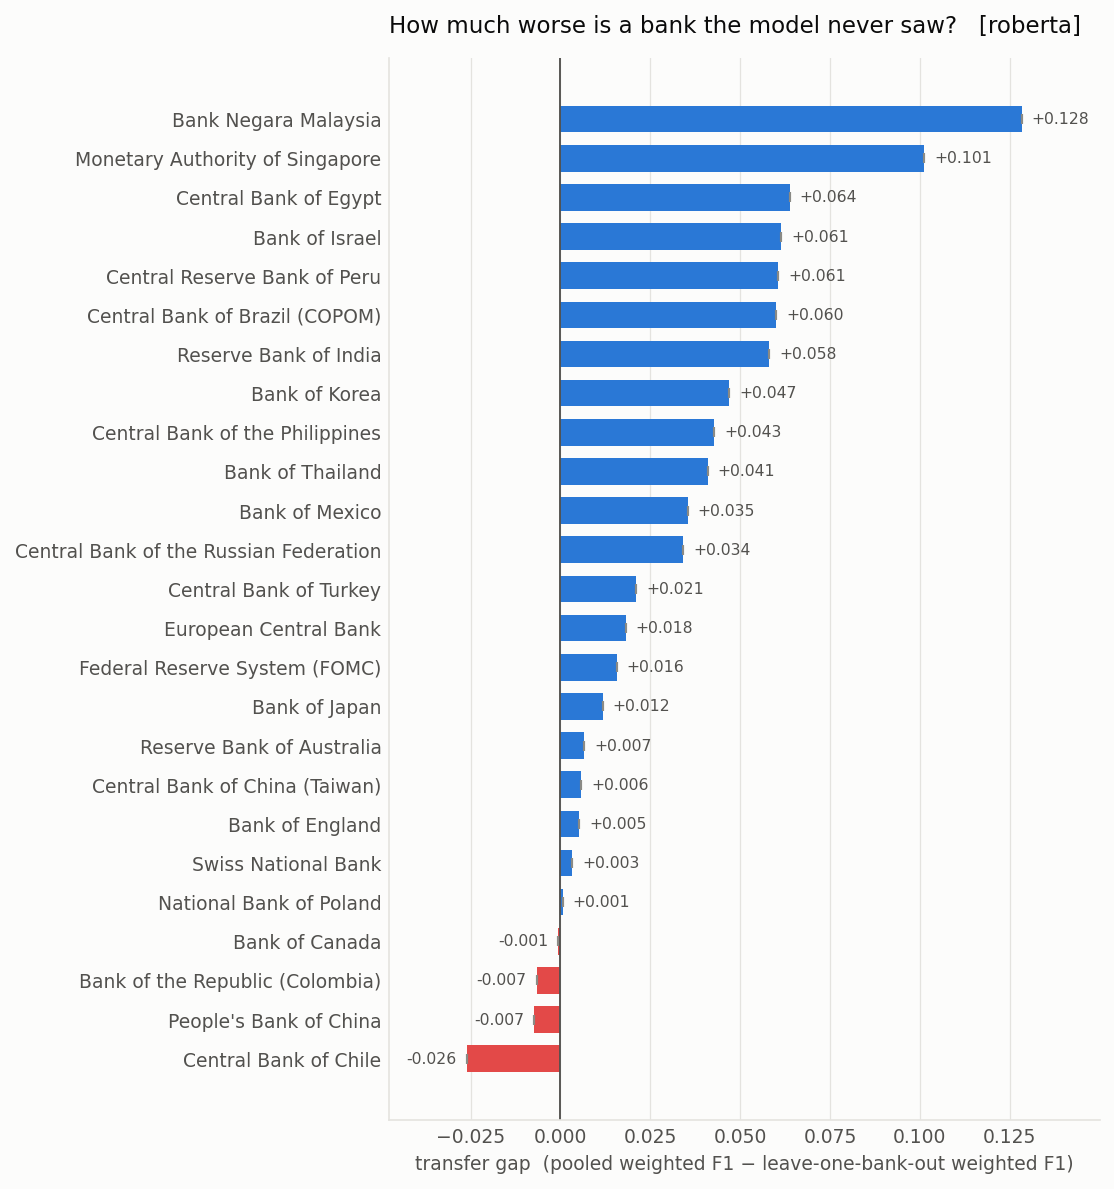

/content/drive/MyDrive/cs72_final_project/figures/roberta_fig2_gap_decomposition.png


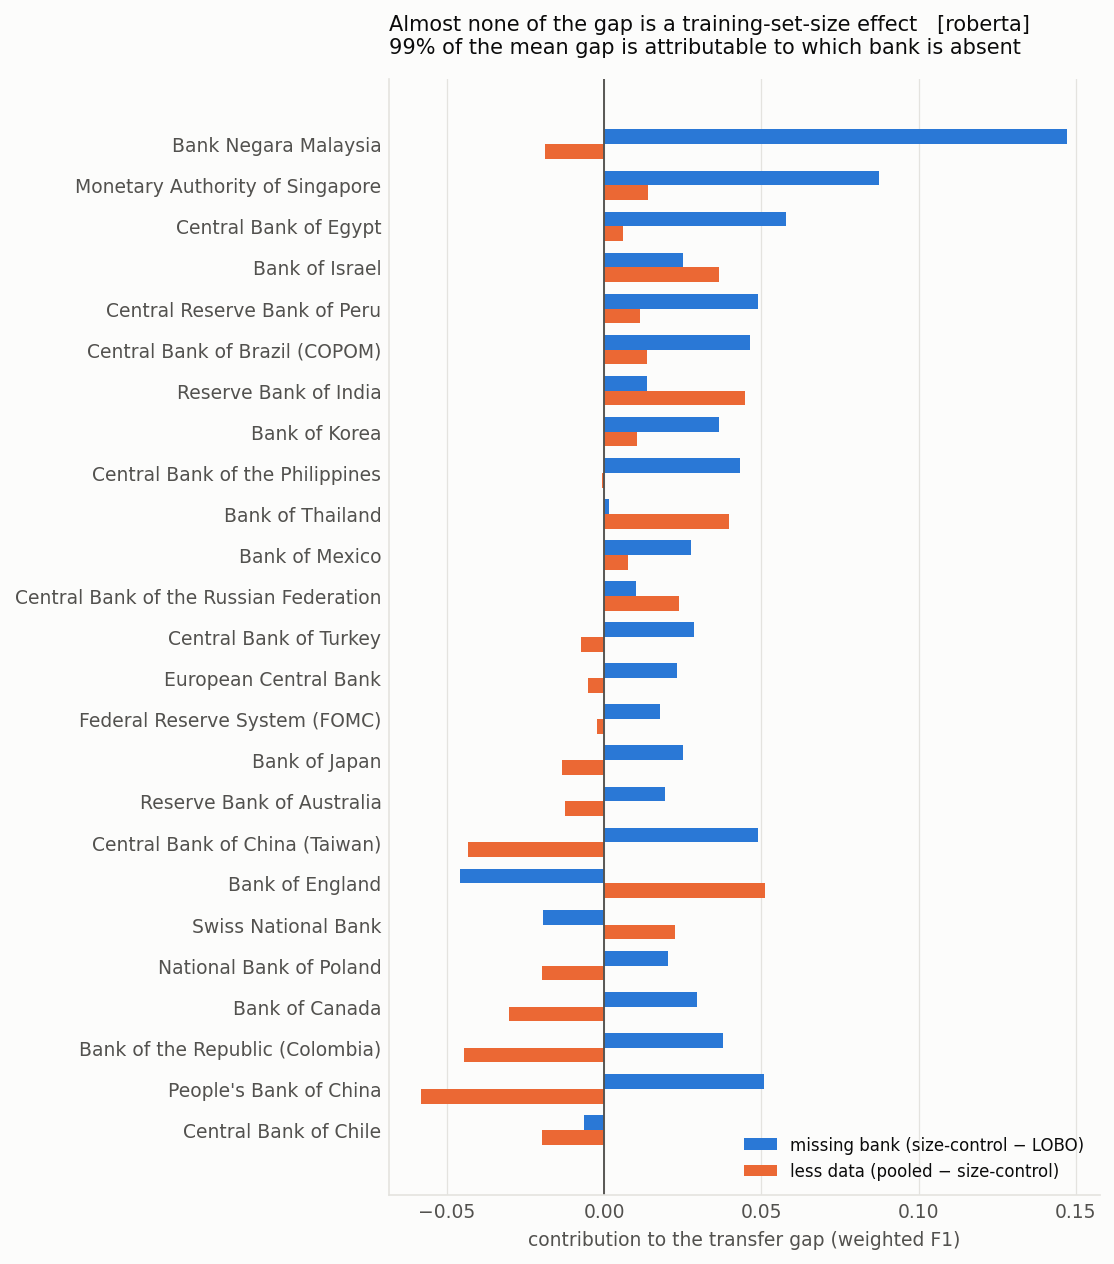

/content/drive/MyDrive/cs72_final_project/figures/roberta_fig3_features.png


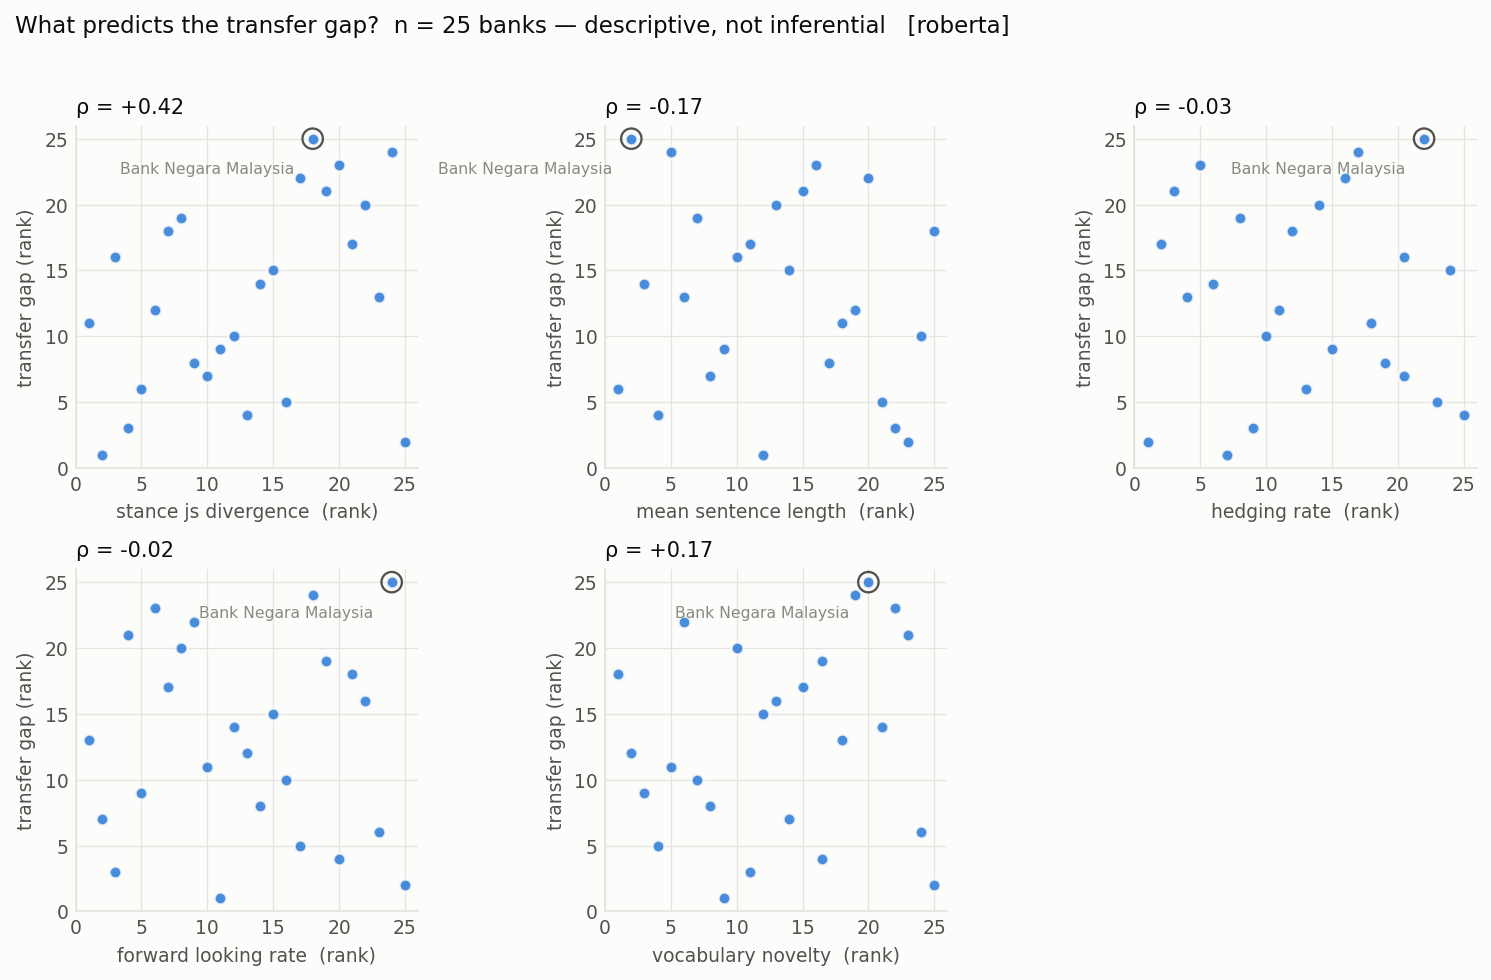

/content/drive/MyDrive/cs72_final_project/figures/roberta_fig4_per_class_f1.png


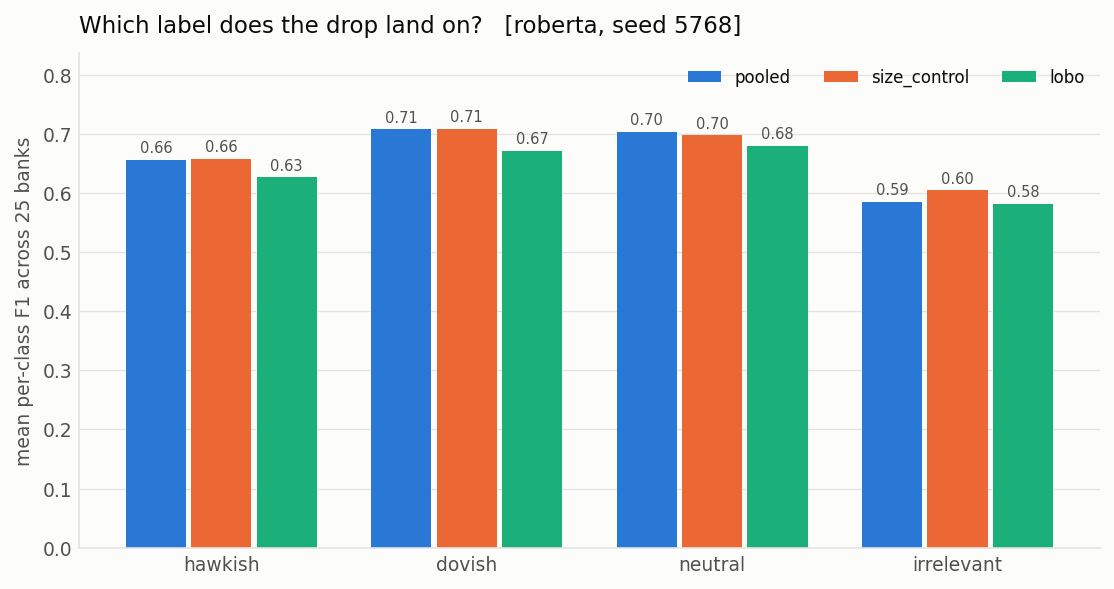

In [7]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob(f"{C.FIGURES_DIR}/roberta_fig*.png")):
    print(f); display(Image(f))

### Bring the baseline results across

The TF-IDF results were produced on your laptop and live in the repo, while Colab writes
to Drive. Copying them over lets `make_report.py` run for both models in one place, so
the writeup can put RoBERTa and the baseline side by side.

In [8]:
import shutil, pathlib
src = pathlib.Path('/content/final_project/results/baseline')
dst = pathlib.Path(C.RESULTS_DIR) / 'baseline'
if src.exists() and not dst.exists():
    shutil.copytree(src, dst)
    print('copied', len(list(dst.rglob('*.json'))), 'baseline fold results to Drive')
else:
    print('already present' if dst.exists() else 'no baseline results in the archive')

!python scripts/make_report.py --model baseline

copied 225 baseline fold results to Drive
model=baseline  seeds=[np.int64(5768), np.int64(78516), np.int64(944601)]  folds=225
dedup: train 17500->17468 (-32), val 3750->3749 (-1), test 3750 (untouched)
wrote /content/drive/MyDrive/cs72_final_project/figures/baseline_fig1_transfer_gap.png
wrote /content/drive/MyDrive/cs72_final_project/figures/baseline_fig2_gap_decomposition.png
wrote /content/drive/MyDrive/cs72_final_project/figures/baseline_fig3_features.png
wrote /content/drive/MyDrive/cs72_final_project/figures/baseline_fig4_per_class_f1.png

=== baseline: headline numbers ===
  pooled weighted F1 (mean over banks) : 0.6113
  LOBO   weighted F1 (mean over banks) : 0.5585
  transfer gap                         : +0.0528
    of which, less training data       : +0.0028
    of which, the bank being absent    : +0.0500
  banks with a positive gap            : 24/25

  largest gap: People's Bank of China (+0.2952)

=== feature correlations with the gap (n=25) ===
             feature  s

## Stage 9 — how much progress have I made?

Safe to run at any time, including after a disconnect.

In [ ]:
import glob, os
for cond in ('pooled', 'size_control', 'lobo'):
    done = glob.glob(f"{C.RESULTS_DIR}/roberta/seed5768/{cond}/*.json")
    print(f"{cond:<14} {len(done):>2}/{len(C.BANKS) if cond=='lobo' else len(C.BANKS)} banks scored")
missing = [b for b in C.BANKS
           if not os.path.exists(f"{C.RESULTS_DIR}/roberta/seed5768/lobo/{b}.json")]
print("\nLOBO folds still to run:", missing or "none - sweep complete")